**Student ID:** `0001184186`
**Full name:** `Saad Qasim Abbasi`
**Institutional email:** `saadqasim.abbasi@studio.unibo.it`

# Person Search on PRW: detection + re-identification

**Task.** Given a *query* crop of a person, find every occurrence of that person in a gallery of 6,112 full test frames from the PRW dataset (*Person Re-identification in the Wild*). The system has to **detect** all people in each gallery frame and **re-identify** them, i.e. rank the detections by their similarity to the query.

**What this notebook does.** It is **inference/evaluation only**. No training happens here. The trained weights are loaded from a public Kaggle dataset, and every system is evaluated on the official PRW test split (2,057 queries) with the **official `eval_search_prw`** function. The code and the four training notebooks that produced the weights are in the GitHub repository [SaadQAbbasi/ML4CV-Assignment](https://github.com/SaadQAbbasi/ML4CV-Assignment). Its `README.md` explains how to retrain each model.

**How to run: on Kaggle.** No accounts, tokens or secrets are needed.
1. Open the public Kaggle version of this notebook and click **Copy & Edit**. The three inputs below are already attached. If you upload `main.ipynb` to a new Kaggle notebook instead, attach them with *Add Input*:

   | Input | Kaggle dataset | Content |
   |---|---|---|
   | PRW dataset | `edoardomerli/prw-person-re-identification-in-the-wild` | frames, annotations, queries |
   | Code | `saadqasimabbasi/prw-person-search-code` | the project `.py` modules + a DINOv3 code snapshot |
   | Weights | `saadqasimabbasi/prw-person-search-weights` | the five trained checkpoints (`.pt`) |

2. Settings: **Accelerator → GPU T4 ×1 (or P100)**. Internet is not required.
3. **Run All.** The inputs are located automatically. A full run takes about **1 h 55 min** on a T4. Almost all of it is the evaluation cell in section 3, which embeds the 6k gallery frames four times. Each code cell below states its measured run time.
4. **Optional quick run (≈ 10 min).** To check that the notebook runs end to end without waiting for the full evaluation, set `QUICK_RUN = True` in the configuration cell of section 2.2 before *Run All*. Every system is then evaluated on only the first 300 test frames, and all sections still produce their tables and figures. **The quick-run metrics are not comparable to the reported results**, which are the saved outputs of a full run with `QUICK_RUN = False` (the default).

### Contents
0. [Pipeline and compared systems](#pipeline)
1. [Setup: code, dependencies, data and weights](#setup)
2. [Imports and experiment configuration](#config)
3. [Evaluation protocol and full test-set evaluation](#evaluation)
4. [Quantitative results and ablation discussion](#results)
5. [Embedding-space analysis](#embeddings)
6. [Qualitative results: top-5 retrievals](#qualitative)
7. [Conclusions and limitations](#conclusions)

<a id="pipeline"></a>
## 0. Pipeline and compared systems

Every system answers a query in the same two steps: **detect** the people in each gallery frame (a Faster R-CNN with FPN; detections with confidence ≥ 0.5 are kept), then **embed** every detection and the query crop into an L2-normalised vector. Gallery detections are ranked by **cosine similarity** to the query.

The systems differ in **where the ReID embedding of a detected person comes from**:

**Single-pass: re-use the detector's own features.** The frame goes through the Swin-T backbone + FPN **once**. The detection head predicts the boxes, and for each box RoIAlign cuts a 7×7 window out of the **feature maps that were already computed for detection**. A small trained ReID head turns that window into the embedding. The image pixels are never looked at again: the person is described only by the frozen detector features, at the reduced resolution of the FPN map.

```
frame ──► Swin-T backbone + FPN (frozen, run once) ──► feature maps ─┬─► detection head ──► boxes
                                                                     │                        │
                                                                     └──► RoIAlign 7×7 ◄──────┘ ──► ReID head ──► embedding
```

**Two-pass: crop the pixels again and re-encode them.** The detector is used **only to find the boxes**. Each box is then cut out of the **original full-resolution frame**, resized to a person crop (256×128) and passed through a **second, separate network** trained only for ReID. The embedding therefore comes from the raw pixels of the person, not from the detector's features.

```
pass 1:  frame ──► detector ──► boxes
pass 2:  boxes ──► crop ORIGINAL pixels, resize to 256×128 ──► ReID encoder (separate network) ──► embedding
```

In both designs the query crop goes through the same embedding path as the gallery boxes.

**One-step vs two-step.** In the person-search literature, a *two-step* method uses separate networks for detection and ReID, while a *one-step* method uses one shared network for both. With that terminology:
- **Swin two-pass** and **Swin + DINO** are two-step: the detector and the ReID encoder are separate networks.
- **Swin single-pass** is one-step at inference: one forward pass of the frame produces both boxes and embeddings. It is trained in two stages, though: first the detector, then only the ReID head on its frozen features.
- **ResNet baseline** is a jointly trained one-step network. For evaluation, its detected boxes are cropped from the original pixels and re-encoded by the *same* shared backbone, so at inference it runs two passes through one network.

| System | Detector | Gallery ReID path | ReID training | What it tests |
|---|---|---|---|---|
| **ResNet baseline (crop)** | ResNet-50 Faster R-CNN, trained jointly with ReID | Original-pixel crops re-encoded by the *shared* detector backbone | SupCon, optimised jointly with the detection losses | Starting point: one jointly trained network |
| **Swin single-pass** | Swin-T Faster R-CNN, 512×768, detection-only fine-tuning | Frozen scene features → RoIAlign → trained RoI head | Crop-to-scene SupCon; only the ReID head is trained | Can the *detector's* features be reused for ReID? |
| **Swin two-pass** | same Swin-T detector (frozen) | Original-pixel crops → separate ImageNet Swin-T, global + upper/lower-half pooling | Crop-to-crop SupCon; last two stages fine-tuned | Dedicated crop encoder vs shared scene features |
| **Swin + DINO** | same Swin-T detector (frozen) | Original-pixel crops → DINOv3 ViT-S/16, CLS + upper/lower-half patch pooling | Crop-to-crop SupCon; last four blocks fine-tuned | Self-supervised DINOv3 vs supervised Swin-T as the crop encoder |

The three Swin-based systems share **identical detector weights**. Their detected-gallery results therefore differ **only** in the ReID component.

### Ablation design

| Comparison | What changes |
|---|---|
| ResNet baseline → Swin systems | Detector (ResNet-50 → fine-tuned Swin-T) and separating detection from ReID |
| **Swin single-pass → Swin two-pass** | **Where the ReID features come from**: frozen detector features vs a dedicated encoder on re-cropped pixels |
| **Swin two-pass → Swin + DINO** | **Crop encoder backbone only**: supervised ImageNet Swin-T → self-supervised DINOv3 ViT-S. Detector, crop path and upper/lower pooling are the same. |

All systems use the same ReID loss (SupCon, a multi-positive InfoNCE, temperature 0.1), so the loss is not a confounder. Two differences remain: DINO was trained for 120 epochs instead of 50, and the two Swin ReID checkpoints are the latest epoch while DINO and ResNet use the validation-best one.

### 0.1 Architecture of each system
Top row: the detector. Bottom row: the gallery ReID path, where the systems differ. Blue = detector, green = ReID, orange = outputs; a dashed border means the module is frozen during ReID training.

**1. ResNet baseline (crop).** A single ResNet-50 Faster R-CNN is trained **jointly** for detection and ReID. At test time the detected boxes are cut from the original frame and passed through the **same** backbone a second time. The ReID head then embeds the whole crop.

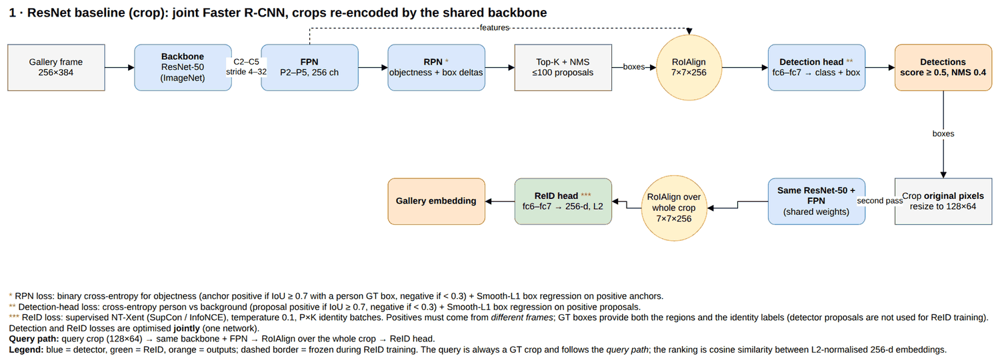

**2. Swin single-pass.** The Swin-T detector is fine-tuned for detection only and then **frozen**. ReID reuses its FPN features: RoIAlign on the final detections feeds a small trained RoI head. There is no second backbone pass for the gallery.

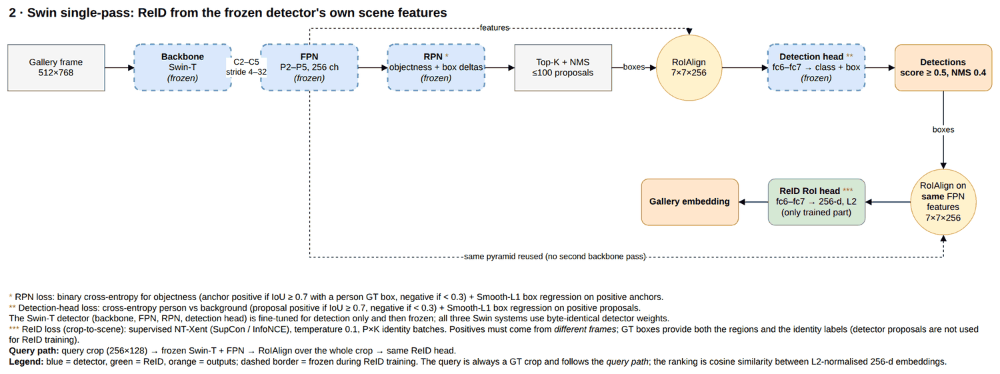

**3. Swin two-pass.** Same frozen detector. Each detection is cropped from the **original pixels** and embedded by an independent ImageNet Swin-T. Its global, upper-half and lower-half features are concatenated and projected to 256-d.

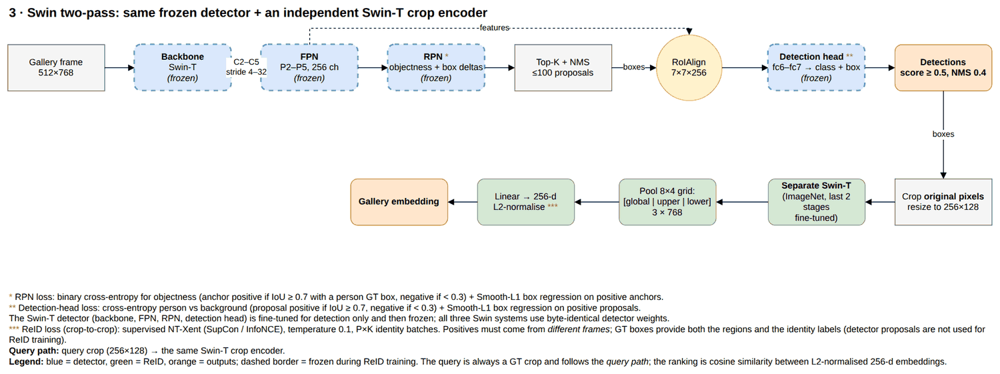

**4. Swin + DINO (final system).** Same frozen detector and crop path. The encoder is a fine-tuned **DINOv3 ViT-S/16**: the CLS token plus the mean of the upper and lower halves of the 16×8 patch grid, projected to 256-d.

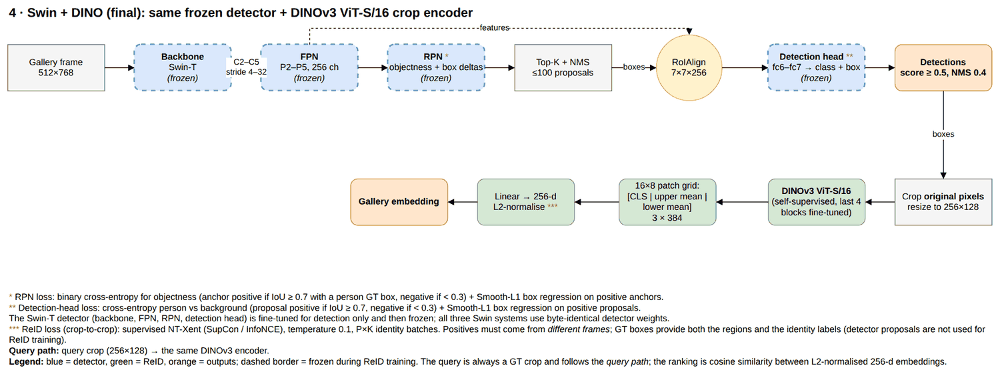

<a id="setup"></a>
## 1. Setup: locate the Kaggle inputs

The model and evaluation code lives in plain Python modules (the `src/` folder of the repository), provided here by the **code** input dataset. This cell finds the three inputs (code, PRW, weights) under `/kaggle/input`, adds the code to the Python path and selects the GPU. It stops with a clear message if an input is missing. Results are written to `/kaggle/working/final_prw_comparison`.

> **Run time (Kaggle T4):** ≈ 10 s

In [1]:
import os
import sys
from pathlib import Path

import torch

KAGGLE_INPUT = Path("/kaggle/input")
if not KAGGLE_INPUT.is_dir():
    raise RuntimeError("This notebook is meant to run on Kaggle with the PRW, code and weights datasets attached.")

PROJECT_MODULES = {"final_comparison.py", "prw_evaluation.py", "official_evaluation.py", "eval_function.py",
                   "model.py", "swin_reid.py", "dinov3_reid.py"}
WEIGHT_FILES = {"resnet_baseline.pt", "swin_single_pass.pt", "swin_two_pass.pt",
                "swin_dino_reid.pt", "swin_detector.pt"}
SKIPPED_FOLDERS = {"frames", "annotations", "query_box", ".git"}  # thousands of images, nothing to find


def scan_inputs():
    """Walk /kaggle/input once and return the code, DINOv3, PRW and weight locations."""
    code_dir = dinov3_dir = prw_root = None
    weights = {}
    for directory, subfolders, files in os.walk(KAGGLE_INPUT):
        directory = Path(directory)
        if prw_root is None and "query_info.txt" in files and "frames" in subfolders:
            prw_root = directory
        subfolders[:] = [name for name in subfolders if name not in SKIPPED_FOLDERS]
        if code_dir is None and PROJECT_MODULES.issubset(files):
            code_dir = directory
        if dinov3_dir is None and "hubconf.py" in files and directory.name.startswith("dinov3"):
            dinov3_dir = directory
        for name in WEIGHT_FILES.intersection(files):
            weights.setdefault(name, directory / name)
    return code_dir, dinov3_dir, prw_root, weights


CODE_DIR, DINOV3_DIR, PRW_ROOT, WEIGHT_PATHS = scan_inputs()
missing = [label for label, value in [("code dataset (project .py files)", CODE_DIR),
                                      ("PRW dataset", PRW_ROOT)] if value is None]
missing += [f"weight file {name}" for name in sorted(WEIGHT_FILES - set(WEIGHT_PATHS))]
if missing:
    raise FileNotFoundError("Missing Kaggle inputs (see 'How to run'): " + ", ".join(missing))
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

OUTPUT = Path("/kaggle/working/final_prw_comparison")
OUTPUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    print("WARNING: no GPU found; enable a GPU accelerator in the notebook settings (CPU would take many hours).")

print("Code:    ", CODE_DIR)
print("DINOv3:  ", DINOV3_DIR or "not bundled; the code will be fetched from GitHub (needs Internet)")
print("PRW:     ", PRW_ROOT)
print("Weights: ", *[f"{name}: {path}" for name, path in sorted(WEIGHT_PATHS.items())], sep="\n  ")
print("Device:  ", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Code:     /kaggle/input/datasets/saadqasimabbasi/prw-person-search-code
DINOv3:   /kaggle/input/datasets/saadqasimabbasi/prw-person-search-code/dinov3
PRW:      /kaggle/input/datasets/edoardomerli/prw-person-re-identification-in-the-wild
Weights: 
  resnet_baseline.pt: /kaggle/input/datasets/saadqasimabbasi/prw-person-search-weights/resnet_baseline.pt
  swin_detector.pt: /kaggle/input/datasets/saadqasimabbasi/prw-person-search-weights/swin_detector.pt
  swin_dino_reid.pt: /kaggle/input/datasets/saadqasimabbasi/prw-person-search-weights/swin_dino_reid.pt
  swin_single_pass.pt: /kaggle/input/datasets/saadqasimabbasi/prw-person-search-weights/swin_single_pass.pt
  swin_two_pass.pt: /kaggle/input/datasets/saadqasimabbasi/prw-person-search-weights/swin_two_pass.pt
Device:   cuda Tesla T4


<a id="config"></a>
## 2. Imports and configuration

### 2.1 Imports
The main project helpers are `load_system` (rebuilds a system from its checkpoint), `evaluate_prw` (detects and embeds the gallery, embeds the queries and scores them with the official `eval_search_prw`) and the plotting functions used in sections 5–6.

> **Run time (Kaggle T4):** ≈ 10 s

In [2]:
import gc
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from final_comparison import (load_system, fixed_occurrences,
                              occurrence_embeddings, plot_embeddings, plot_similarities,
                              plot_matched_query)
from prw_evaluation import evaluate_prw

### 2.2 Systems and settings
`SYSTEMS` lists the four systems and their checkpoint files. The `artifact` / `run_id` fields only record which W&B run each file came from. The DINO checkpoint holds only the ReID encoder, so it is combined with the shared Swin detector (`DETECTOR`).

Settings, the same for every system:
- `SCORE_THRESHOLD = 0.5`: minimum detector confidence for a box to enter the gallery (not tuned on the test set).
- `IOU_THRESHOLD = 0.5`: overlap needed for a detection to count as the query person.
- `NUM_VISUAL_IDS`, `OCCURRENCES_PER_ID`, `SEED`: size of the fixed sample used for the plots in section 5.
- `QUICK_RUN` (default `False`): set it to `True` for a quick end-to-end test (≈ 10 min on a T4). The gallery is cut to the first `QUICK_GALLERY_FRAMES = 300` test frames, so **its numbers are not comparable to the reported results**. The saved outputs come from a full run with `QUICK_RUN = False`.

> **Run time (Kaggle T4):** < 1 s

In [3]:
PROVENANCE = "models-alma-mater-studio/person-search/"  # W&B project the weights were exported from

SYSTEMS = [
    dict(name="ResNet baseline (crop)", kind="resnet_crop", weights_file="resnet_baseline.pt",
         selection="validation best", expected_metric_loss="supcon", crop_size=(128, 64),
         artifact=PROVENANCE + "prw-best-model:v6", run_id="jw7ysc43",
         training_note="Joint detection + ReID, SupCon; crops re-encoded by the shared backbone"),
    dict(name="Swin single-pass", kind="swin_scene", weights_file="swin_single_pass.pt",
         selection="latest epoch (50)",
         artifact=PROVENANCE + "swin-reid-crop_to_scene-latest:v4", run_id="vdrppx5p",
         training_note="Frozen scene backbone; trained RoI head"),
    dict(name="Swin two-pass", kind="swin_crop", weights_file="swin_two_pass.pt",
         selection="latest epoch (50)",
         artifact=PROVENANCE + "swin-reid-crop_to_crop-latest:v4", run_id="tv1tvl2u",
         training_note="Separate Swin-T crop encoder"),
    dict(name="Swin + DINO", kind="dino", weights_file="swin_dino_reid.pt",
         selection="validation best",
         artifact=PROVENANCE + "prw-dinov3-last4-p16k4-upper-lower-infonce-256x128-valmap-best-model:v23",
         run_id="xhdye71i",
         training_note="DINOv3 CLS + upper/lower, four trainable blocks; longer training budget"),
]
# Fine-tuned Swin-T detector shared by the DINO system.
DETECTOR = dict(name="Swin detector", weights_file="swin_detector.pt",
                artifact=PROVENANCE + "swin-detector-512x768-best:v0", run_id="77d9acgi")

SCORE_THRESHOLD = .5      # same detector operating point for every system
IOU_THRESHOLD = .5        # IoU for a detection to count as the query person (in-house ranking)
NUM_VISUAL_IDS = 20       # identities in the fixed diagnostic sample
OCCURRENCES_PER_ID = 8    # distinct test frames per diagnostic identity
SEED = 0

# Quick run: set QUICK_RUN = True for an end-to-end smoke test (about 10 min on a T4 instead of about 1 h 55 min).
# The gallery is cut to the first QUICK_GALLERY_FRAMES test frames, so its metrics are NOT comparable to the
# reported results. The saved outputs of this notebook come from a full run with QUICK_RUN = False.
QUICK_RUN = False
QUICK_GALLERY_FRAMES = 300

# Attach the file paths found in /kaggle/input (section 1).
for spec in SYSTEMS:
    spec["checkpoint_path"] = str(WEIGHT_PATHS[spec["weights_file"]])
    if spec["kind"] == "dino" and DINOV3_DIR is not None:
        spec["dinov3_repo"] = str(DINOV3_DIR)
detector_path = WEIGHT_PATHS[DETECTOR["weights_file"]]
display(pd.DataFrame(SYSTEMS)[["name", "kind", "selection", "checkpoint_path", "training_note"]])
if QUICK_RUN:
    print(f"QUICK RUN: gallery limited to the first {QUICK_GALLERY_FRAMES} test frames; "
          "metrics are not comparable to the reported results.")


,name,kind,selection,checkpoint_path,training_note
0,ResNet baseline (crop),resnet_crop,validation best,/kaggle/input/datasets/saadqasimabbasi/prw-per...,"Joint detection + ReID, SupCon; crops re-encod..."
1,Swin single-pass,swin_scene,latest epoch (50),/kaggle/input/datasets/saadqasimabbasi/prw-per...,Frozen scene backbone; trained RoI head
2,Swin two-pass,swin_crop,latest epoch (50),/kaggle/input/datasets/saadqasimabbasi/prw-per...,Separate Swin-T crop encoder
3,Swin + DINO,dino,validation best,/kaggle/input/datasets/saadqasimabbasi/prw-per...,"DINOv3 CLS + upper/lower, four trainable block..."


<a id="evaluation"></a>
## 3. Evaluation

**Metric.** mAP and top-1 are computed by the official `eval_search_prw` provided with the assignment, used unmodified. Each of the 2,057 test queries is searched in all 6,112 test frames except its own frame. The system returns one ranked list of all gallery boxes, sorted by cosine similarity to the query. A box counts as a **correct match** if it overlaps the query person's ground-truth box with IoU ≥ 0.5 (at most one correct box per frame).

- **Top-1:** the fraction of queries whose **first** result is a correct match.
- **mAP:** measures how high *all* the correct matches are placed in the ranking, not just the first one. For one query:
  1. Go down the ranked list. Each time a correct match appears, compute the precision at that point: correct matches so far ÷ results seen so far.
  2. The **average precision (AP)** is the mean of these precisions. It is 1 only if every correct match is ranked above every wrong box.
  3. The official function then multiplies the AP by the detector's **recall** for that person: the fraction of their appearances in the gallery that the detector found. A person the detector misses in half of the frames can therefore reach at most 0.5.

  **mAP** is the mean AP over all queries. For example, if a person appears in 4 other frames and the correct boxes are ranked 1, 2, 5 and 10, then AP = (1/1 + 2/2 + 3/5 + 4/10) / 4 = 0.75.

**Detected vs GT gallery.** Every system is evaluated twice. These are the `detected` and `gt` columns in all tables and charts below:
- **detected:** the gallery is the boxes found by the detector. This is the real person-search task and gives the main results.
- **gt:** the gallery is the annotated ground-truth boxes, i.e. a *perfect detector*. It measures the ReID part alone. The gap between the two shows how much detection errors cost.

**The next cell**, for each system, loads the model, evaluates both galleries, saves the results to `OUTPUT`, and embeds a fixed sample of 20 identities × 8 frames for the plots in section 5. The sample is drawn before any model is loaded, so it cannot favour any of them. The cell also checks that the three Swin systems use identical detector weights.

> **Run time (Kaggle T4):** ≈ 1 h 50 min (≈ 27 min per system). This is the only slow cell. With `QUICK_RUN = True` it takes a few minutes.  
> **Saved output:** the progress messages were removed for readability. For each system it shows the mAP / top-1 printed by `eval_search_prw`, first for the detected gallery, then for the GT gallery.

In [4]:
# Fixed diagnostic sample, chosen before any model is loaded.
sample = fixed_occurrences(PRW_ROOT, NUM_VISUAL_IDS, OCCURRENCES_PER_ID, SEED)
(OUTPUT / "visualization_sample.json").write_text(json.dumps(sample, indent=2))
print("Visualization identity IDs:", sorted({r["identity"] for r in sample}))

rows = []
provenance = {}
banks = {}               # per-system embeddings of the diagnostic sample
retrieval_records = {}   # per-(system, gallery mode) ranked results for the first queries
shared_detector = None
for index, spec in enumerate(SYSTEMS):
    print("Evaluating:", spec["name"])
    model, info = load_system(spec, detector_path, DEVICE)

    # All Swin-based systems must use byte-identical detector weights and resolution.
    if not spec["kind"].startswith("resnet"):
        signature = (info["detector_sha256"], info["detector_image_size"],
                     json.dumps(info["detector_config"], sort_keys=True))
        if shared_detector is None:
            shared_detector = signature
        elif signature != shared_detector:
            raise RuntimeError("Detector weights/resolution differ: comparison stopped")
    provenance[spec["name"]] = info

    # Full test-set evaluation with detected and ground-truth galleries.
    for mode in ("detected", "gt"):
        started = time.perf_counter()
        result = evaluate_prw(model, PRW_ROOT, DEVICE, score_threshold=SCORE_THRESHOLD,
                              iou_threshold=IOU_THRESHOLD, detector_image_size=info["detector_image_size"],
                              gallery_embedding_mode=info["gallery_embedding_mode"], gallery_mode=mode,
                              official_eval=True, return_records=True, table_queries=100, table_top_k=5,
                              max_gallery=QUICK_GALLERY_FRAMES if QUICK_RUN else None,
                              batch_size=2, query_batch_size=32, gallery_crop_batch_size=32)
        records = result.pop("retrieval_records")
        retrieval_records[(spec["name"], mode)] = records
        row = dict(system=spec["name"], checkpoint_epoch=info["epoch"], selection=spec["selection"],
                   evaluation_wall_seconds=time.perf_counter() - started, **result)
        rows.append(row)
        # Save after each evaluation, before visualization work.
        pd.DataFrame(rows).to_csv(OUTPUT / "metrics.csv", index=False)
        (OUTPUT / f"retrieval-{index}-{mode}.json").write_text(json.dumps(records, indent=2))
        (OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2, default=str))

    # Embeddings of the diagnostic sample (query path and gallery path).
    banks[spec["name"]] = occurrence_embeddings(model, PRW_ROOT, sample, DEVICE,
                                               info["detector_image_size"], info["gallery_embedding_mode"])
    torch.save(banks, OUTPUT / "visualization_embeddings.pt")

    # Free GPU memory before loading the next system.
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

comparison = pd.DataFrame(rows)
display(comparison.drop(columns=["selection"]))

Visualization identity IDs: [98, 239, 427, 496, 544, 563, 662, 663, 686, 695, 716, 724, 731, 736, 780, 821, 832, 872, 891, 907]

Evaluating: ResNet baseline (crop)
PRW evaluation: ranking 2057 queries against 21932 detections
search ranking:
  mAP = 31.73%
  top- 1 = 68.74%
PRW evaluation: ranking 2057 queries against 25062 detections
search ranking:
  mAP = 37.74%
  top- 1 = 73.16%

Evaluating: Swin single-pass
PRW evaluation: ranking 2057 queries against 21583 detections
search ranking:
  mAP = 25.00%
  top- 1 = 54.74%
PRW evaluation: ranking 2057 queries against 25062 detections
search ranking:
  mAP = 27.02%
  top- 1 = 54.79%

Evaluating: Swin two-pass
PRW evaluation: ranking 2057 queries against 21583 detections
search ranking:
  mAP = 45.42%
  top- 1 = 83.67%
PRW evaluation: ranking 2057 queries against 25062 detections
search ranking:
  mAP = 50.24%
  top- 1 = 85.71%

Evaluating: Swin + DINO
PRW evaluation: ranking 2057 queries against 21583 detections
search ranking:
  mAP = 54

,system,checkpoint_epoch,evaluation_wall_seconds,detection_precision_iou50,detection_recall_iou50,detection_precision_iou75,detection_recall_iou75,gallery_mode,retrieval_mAP,retrieval_top1,retrieval_queries,retrieval_gallery_frames,retrieval_detections,official_mAP,official_top1,official_queries
0,ResNet baseline (crop),42,869.735150,0.879902,0.770010,0.541173,0.473586,detected,0.317020,0.687409,2057,6112,21932,0.317341,0.687409,2057
1,ResNet baseline (crop),42,682.695003,NaN,NaN,NaN,NaN,gt,0.377388,0.731648,2057,6112,25062,0.377411,0.731648,2057
2,Swin single-pass,50,881.382049,0.934995,0.805203,0.653153,0.562485,detected,0.249363,0.547399,2057,6112,21583,0.249982,0.547399,2057
3,Swin single-pass,50,755.382922,NaN,NaN,NaN,NaN,gt,0.270175,0.547885,2057,6112,25062,0.270198,0.547885,2057
4,Swin two-pass,50,1025.617513,0.934995,0.805203,0.653153,0.562485,detected,0.453071,0.836655,2057,6112,21583,0.454175,0.836655,2057
5,Swin two-pass,50,672.050429,NaN,NaN,NaN,NaN,gt,0.502381,0.857073,2057,6112,25062,0.502388,0.857073,2057
6,Swin + DINO,120,1007.289561,0.934995,0.805203,0.653153,0.562485,detected,0.539387,0.863879,2057,6112,21583,0.540668,0.864852,2057
7,Swin + DINO,120,655.967566,NaN,NaN,NaN,NaN,gt,0.594704,0.880895,2057,6112,25062,0.594706,0.880895,2057


<a id="results"></a>
## 4. Results

### 4.1 Main results
Official mAP and top-1 (%) for both galleries: **detected** (detector boxes, the real task) and **gt** (ground-truth boxes, a perfect detector).

> **Run time (Kaggle T4):** ≈ 1 s

metric                  mAP (%)        Top-1 (%)       
gallery                detected     gt  detected     gt
system                                                 
ResNet baseline (crop)    31.73  37.74     68.74  73.16
Swin single-pass          25.00  27.02     54.74  54.79
Swin two-pass             45.42  50.24     83.67  85.71
Swin + DINO               54.07  59.47     86.49  88.09

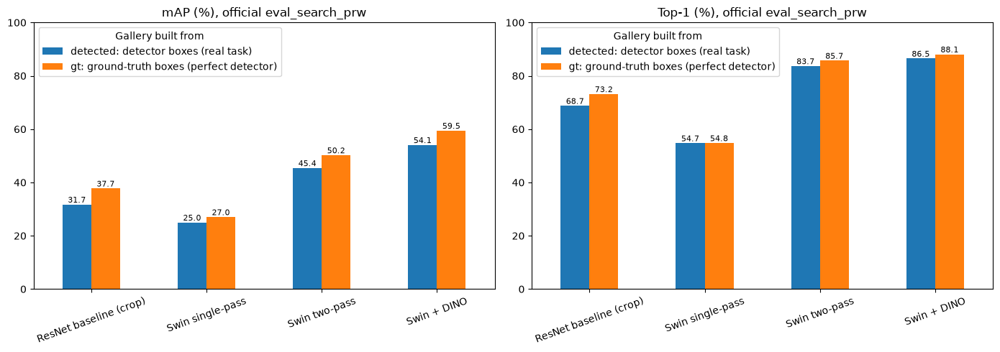

In [5]:
if QUICK_RUN:
    print("QUICK RUN: the numbers below use a reduced gallery and are NOT the reported results.")
systems_order = [s["name"] for s in SYSTEMS]
official = comparison.pivot(index="system", columns="gallery_mode",
                            values=["official_mAP", "official_top1"]).reindex(systems_order) * 100
official.columns = pd.MultiIndex.from_tuples(
    [({"official_mAP": "mAP (%)", "official_top1": "Top-1 (%)"}[metric], mode) for metric, mode in official.columns],
    names=["metric", "gallery"])
display(official.round(2))
official.to_csv(OUTPUT / "official_metrics_percent.csv")

gallery_labels = {"detected": "detected: detector boxes (real task)",
                  "gt": "gt: ground-truth boxes (perfect detector)"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["mAP (%)", "Top-1 (%)"]):
    official[metric].rename(columns=gallery_labels).plot.bar(ax=ax, ylim=(0, 100), rot=20)
    ax.set_title(f"{metric}, official eval_search_prw")
    ax.set_xlabel("")
    ax.legend(title="Gallery built from", loc="upper left")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "official_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

### 4.2 What each change contributes, and detection quality
The first table gives the mAP / top-1 gain of each step (detected gallery). The second gives detector precision and recall at IoU 0.5 and 0.75. The three Swin systems share one detector, so their rows are identical.

> **Run time (Kaggle T4):** < 1 s

In [6]:
detected = official.xs("detected", axis=1, level="gallery")
steps = [("Swin single-pass", "Swin two-pass", "Architecture: dedicated crop encoder vs frozen scene features"),
         ("Swin two-pass", "Swin + DINO", "Crop encoder: self-supervised DINOv3 vs supervised Swin-T"),
         ("ResNet baseline (crop)", "Swin + DINO", "Full change: final system vs baseline")]
ablation = pd.DataFrame([dict(change=label, comparison=f"{before} → {after}",
                              delta_mAP=detected.loc[after, "mAP (%)"] - detected.loc[before, "mAP (%)"],
                              delta_top1=detected.loc[after, "Top-1 (%)"] - detected.loc[before, "Top-1 (%)"])
                         for before, after, label in steps])
with pd.option_context("display.max_colwidth", None):
    display(ablation.round(2))

detection_columns = [c for c in comparison if c.startswith("detection_")]
detection = comparison[comparison.gallery_mode == "detected"].set_index("system")[detection_columns]
detection.columns = [c.replace("detection_", "").replace("_iou", " @ IoU 0.") for c in detection.columns]
display(detection.round(3))

,change,comparison,delta_mAP,delta_top1
0,Architecture: dedicated crop encoder vs frozen scene features,Swin single-pass → Swin two-pass,20.42,28.93
1,Crop encoder: self-supervised DINOv3 vs supervised Swin-T,Swin two-pass → Swin + DINO,8.65,2.82
2,Full change: final system vs baseline,ResNet baseline (crop) → Swin + DINO,22.33,17.74


,precision @ IoU 0.50,recall @ IoU 0.50,precision @ IoU 0.75,recall @ IoU 0.75
system,,,,
ResNet baseline (crop),0.880,0.770,0.541,0.474
Swin single-pass,0.935,0.805,0.653,0.562
Swin two-pass,0.935,0.805,0.653,0.562
Swin + DINO,0.935,0.805,0.653,0.562


### 4.3 Discussion

**1. Single-pass vs two-pass: a dedicated ReID encoder is essential (+20.4 mAP, +28.9 top-1).**
Both systems use exactly the same detector and boxes. They differ only in where the ReID features come from. Features from a detector are trained to be *invariant* to identity: all people should look like "person" to the classifier. A small RoI head on top of those frozen features cannot recover fine identity cues such as clothing texture, accessories or hair. The pooled 512×768 scene features are also low-resolution for small people. Re-encoding the original-pixel crop at 256×128 with a fine-tuned encoder solves both problems. The single-pass system is the only one that scores *below* the ResNet baseline. That baseline also re-encodes crops, which shows the gap comes from the crop path rather than from the backbone. The cost of the two-pass design is a second forward pass per detection.

**2. Self-supervised DINOv3 backbone (+8.6 mAP, +2.8 top-1).**
Swin two-pass and Swin + DINO share the detector, the crop path and the global + upper/lower pooling. Only the crop encoder changes, from supervised ImageNet Swin-T to self-supervised DINOv3 ViT-S/16. DINOv3 is pretrained without labels on a very large image corpus and keeps fine-grained local detail, which helps to tell similar-looking people apart. The gain is mostly in **mAP** (finding *all* occurrences of a person) rather than top-1, so the better embedding helps most on the hard occurrences further down the ranking. *Caveat:* DINO also had a longer training budget (120 vs 50 epochs), so not all of the gain can be attributed to the backbone.

**3. Detection quality.** The fine-tuned Swin-T detector at 512×768 is clearly better than the jointly trained ResNet detector. Precision@0.5 rises from 0.880 to 0.935, recall@0.5 from 0.770 to 0.805, and the gains at IoU 0.75 are larger still (precision 0.541 → 0.653, recall 0.474 → 0.562). Decoupling detection from ReID removed the conflict between the two objectives, and the detector could then be trained at a higher resolution.

**4. Detected vs GT gallery.** Replacing detections with ground-truth boxes improves mAP by only about **5 points** for the two-pass systems (+4.8 for Swin two-pass, +5.4 for DINO), and top-1 by about 2 points. Most of the remaining error therefore comes from **re-identification**, not detection, so further work should go into the ReID embedding first. The ~20% of people the detector misses at IoU 0.5 explain most of that gap, through the recall-rate factor of the official AP.

**5. Comparison with the literature (PRW, approximate published values).** OIM (Xiao et al., 2017) reports about 21 mAP / 49 top-1, NAE (Chen et al., 2020) about 43 / 81, SeqNet (Li & Miao, 2021) about 47 / 83, and the transformer-based COAT (Yu et al., 2022) about 53 / 87. The final system (54.1 / 86.5) is in the range of recent end-to-end methods. The Swin two-pass system alone (45.4 / 83.7) already matches NAE/SeqNet-level results.

<a id="embeddings"></a>
## 5. Embedding-space analysis

Both plots use the fixed sample of 20 test identities × 8 frames, with the same ground-truth boxes for every system.
- **t-SNE of the gallery embeddings.** Each point is one occurrence, coloured by identity. Tight, separate clusters mean that all appearances of a person are embedded close together. t-SNE is fitted per system, so only the cluster structure within each panel is meaningful, not distances across panels.
- **Query vs gallery cosine similarity.** Rows are the occurrences embedded as queries, columns the same occurrences embedded as gallery boxes, grouped by identity. A good model shows a **red block diagonal** (same person, high similarity) on a blue background.

> **Run time (Kaggle T4):** ≈ 5 s

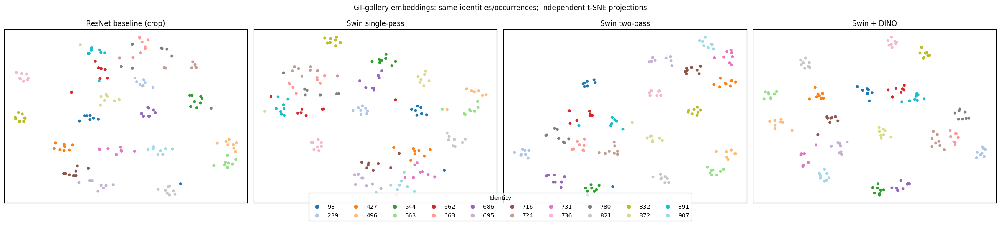

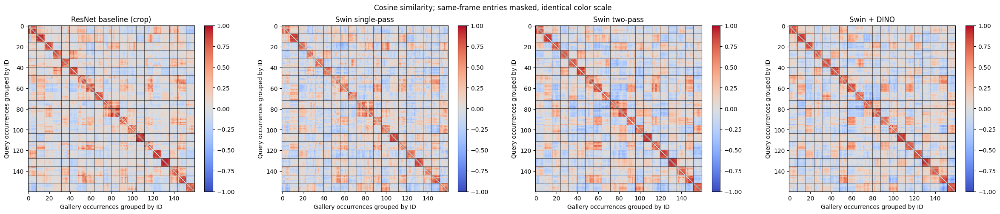

In [8]:
# t-SNE of the diagnostic-sample gallery embeddings (one panel per system).
fig = plot_embeddings(banks, sample, seed=SEED)
fig.savefig(OUTPUT / "tsne.png", dpi=180, bbox_inches="tight")
plt.show()

# Query-path vs gallery-path cosine similarities, grouped by identity.
fig = plot_similarities(banks, sample)
fig.savefig(OUTPUT / "similarity.png", dpi=180, bbox_inches="tight")
plt.show()

### Interpretation
- **Swin single-pass** has the least separated t-SNE, with several identities mixed together. Its similarity matrix has a weak diagonal and many bright off-diagonal blocks, i.e. different people with high similarity. This matches its low mAP: frozen detector features do not separate identities well.
- **ResNet baseline** forms visible clusters but with outliers and some merged identities. Its similarity matrix shows strong off-diagonal stripes: some gallery occurrences are similar to *many* queries, a "hub" effect that pushes wrong matches up the ranking.
- **Swin two-pass** and **Swin + DINO** produce compact, well-separated clusters for almost every identity. Their matrices have the clearest block diagonal on a predominantly blue (dissimilar) background. DINO's clusters are the tightest and its off-diagonal similarity is the lowest, which is consistent with its higher mAP.
- This is a 20-identity illustration. The full-test metrics in section 4 remain the actual measure of performance.

<a id="qualitative"></a>
## 6. Qualitative results: top-5 retrievals

Every system is shown the **same queries**: the first `NUM_EXAMPLE_QUERIES` (10) queries of the official query list `query_info.txt`. They are not picked by identity or by performance. The official list is sorted by person ID, so its first 10 queries belong to only three people (IDs 479, 484, 485), each photographed from different cameras. To see more queries, change `NUM_EXAMPLE_QUERIES` at the top of the next cell (up to 100). Results are saved for the first 100 official queries, which cover 25 people.

In each figure, the rows are the four systems, the left column is the query and the next five columns are the top-5 results from the detected gallery, with their cosine similarity. Green titles are correct matches and red titles are wrong ones.

> **Run time (Kaggle T4):** ≈ 30 s

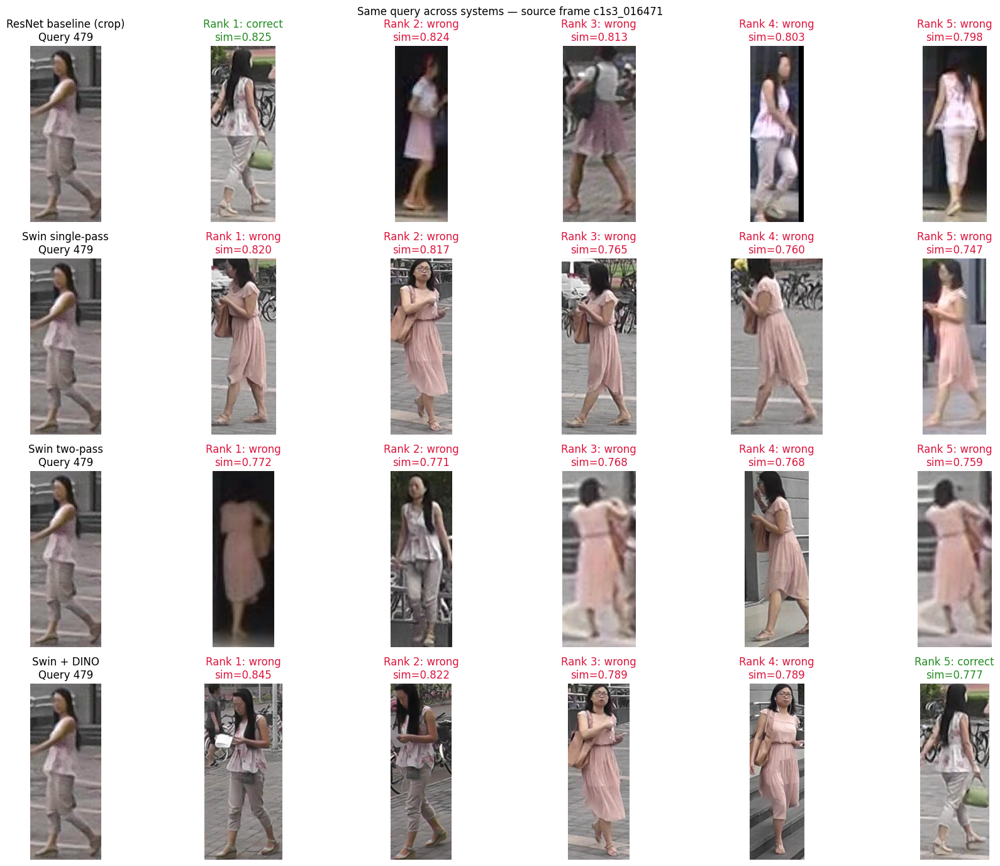

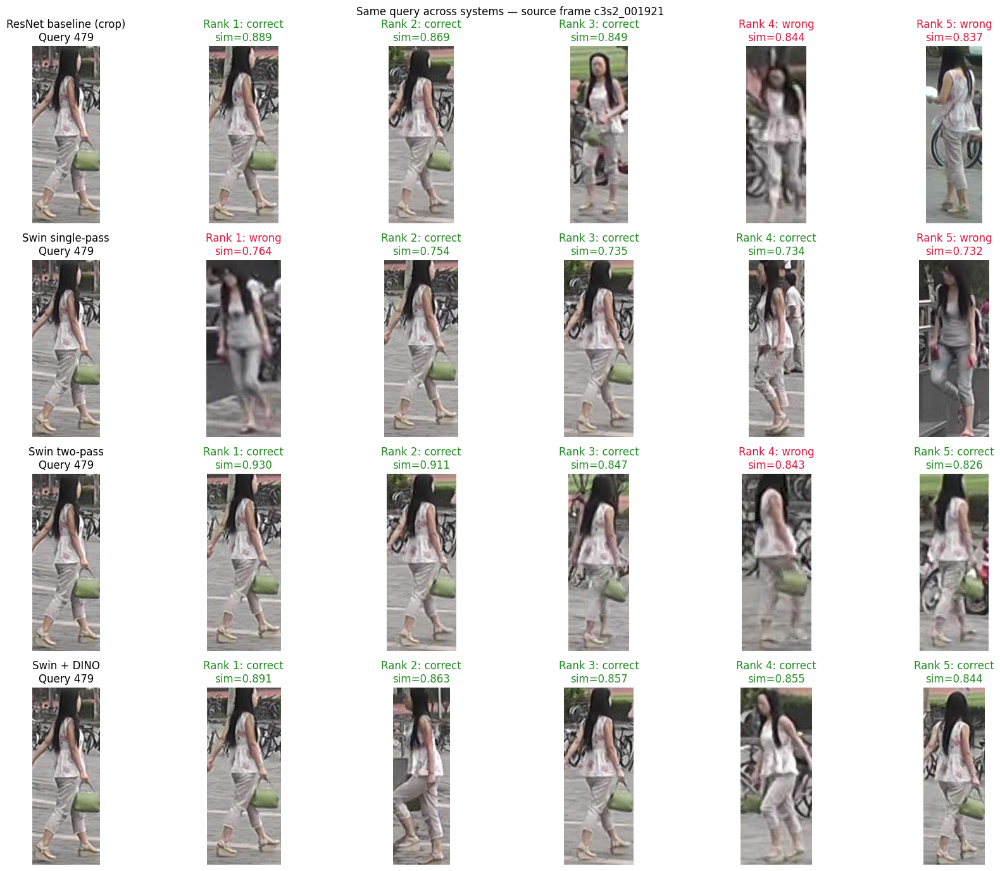

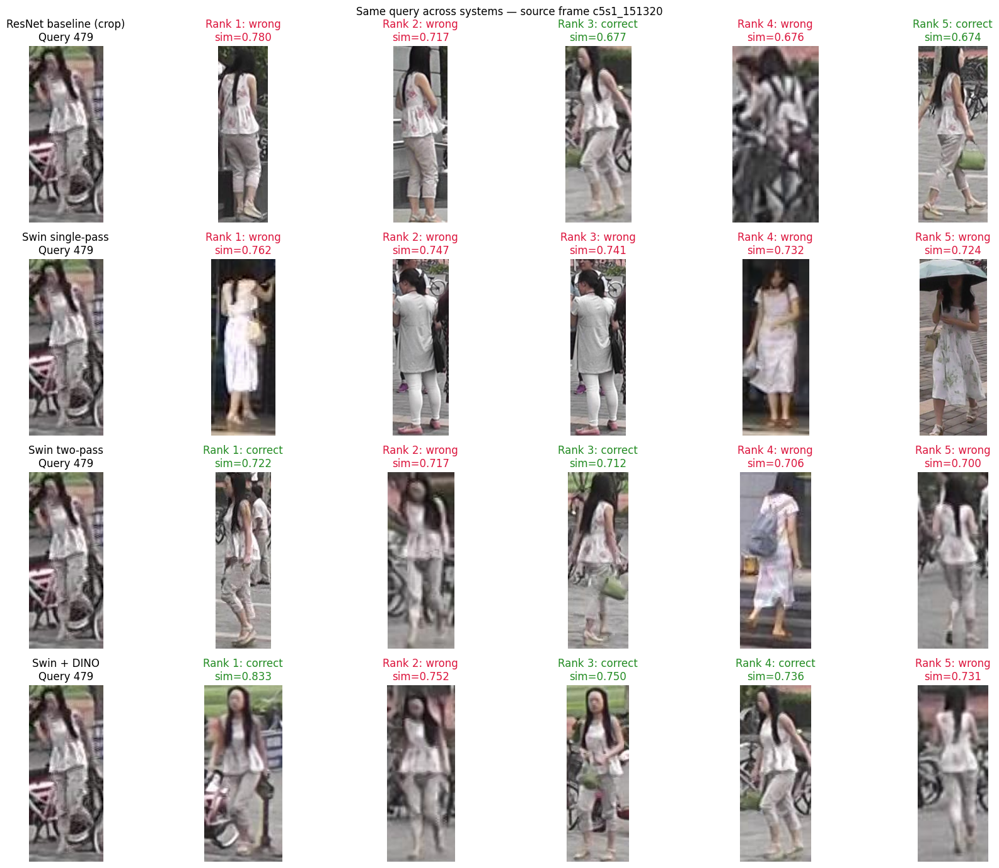

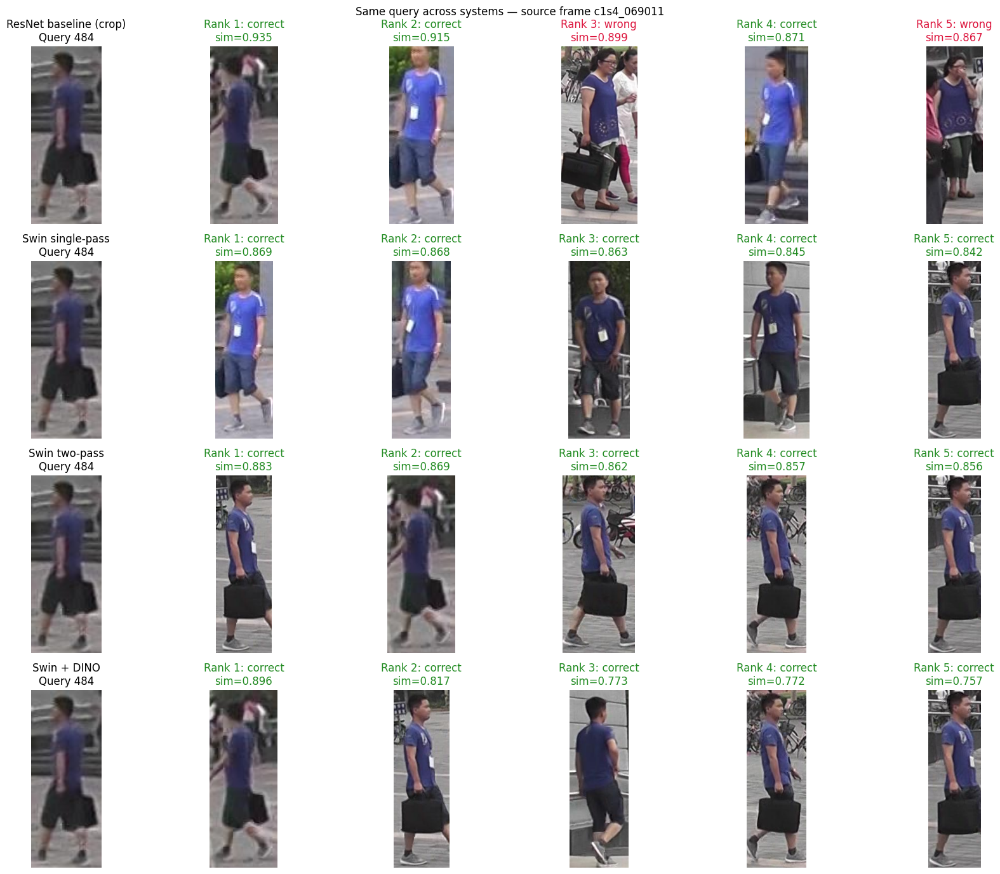

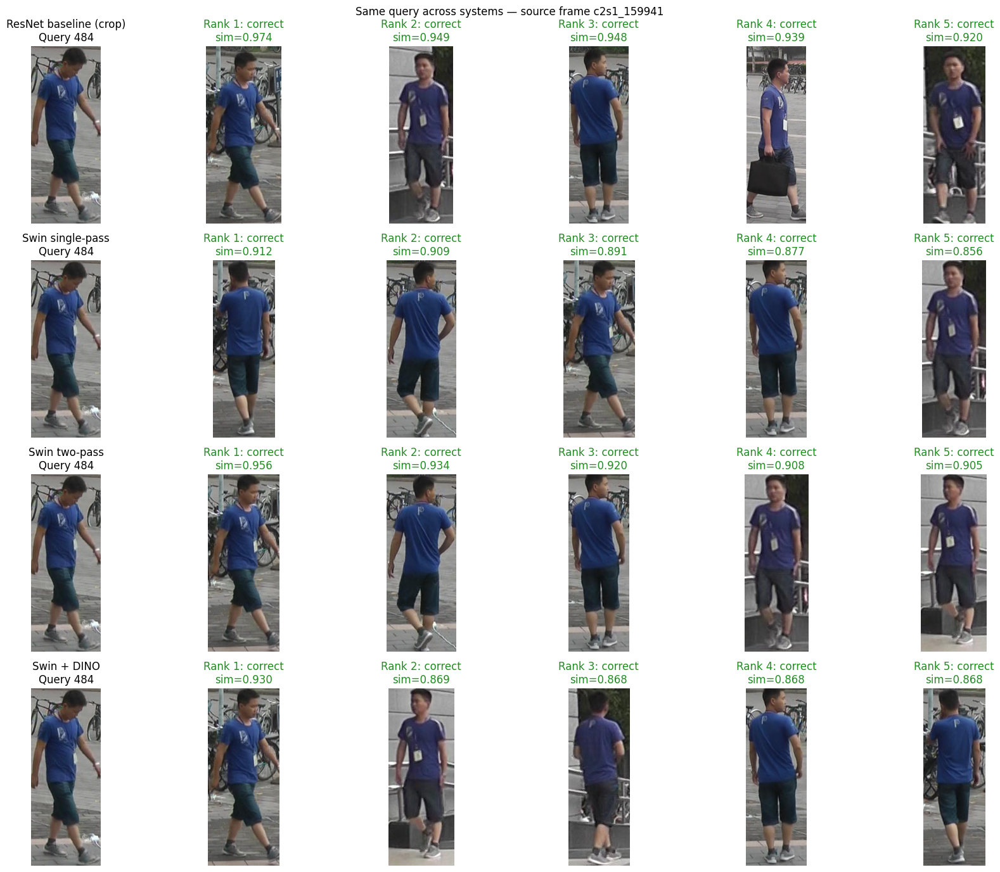

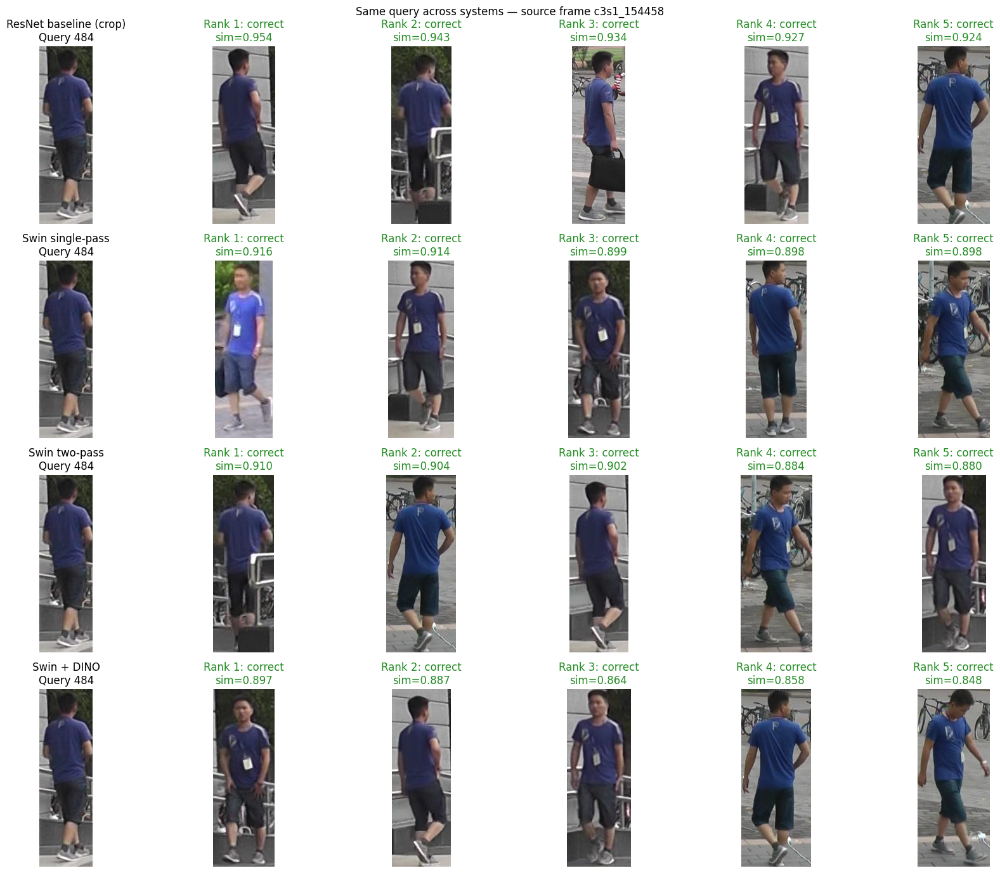

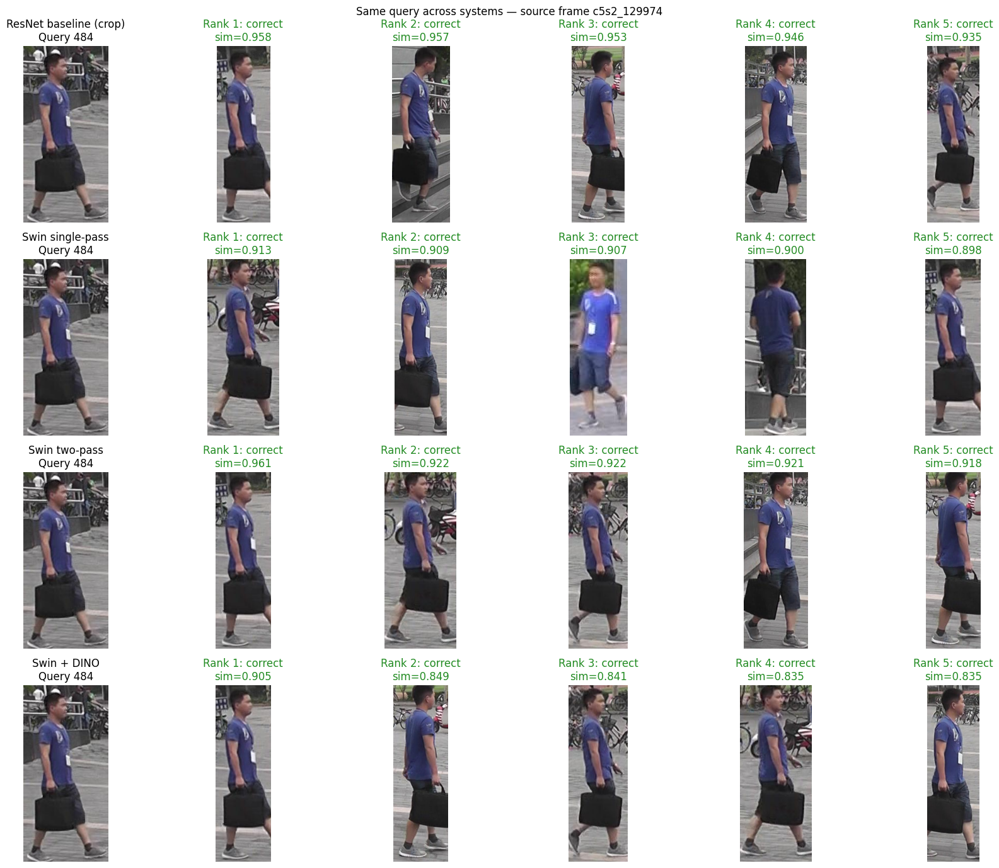

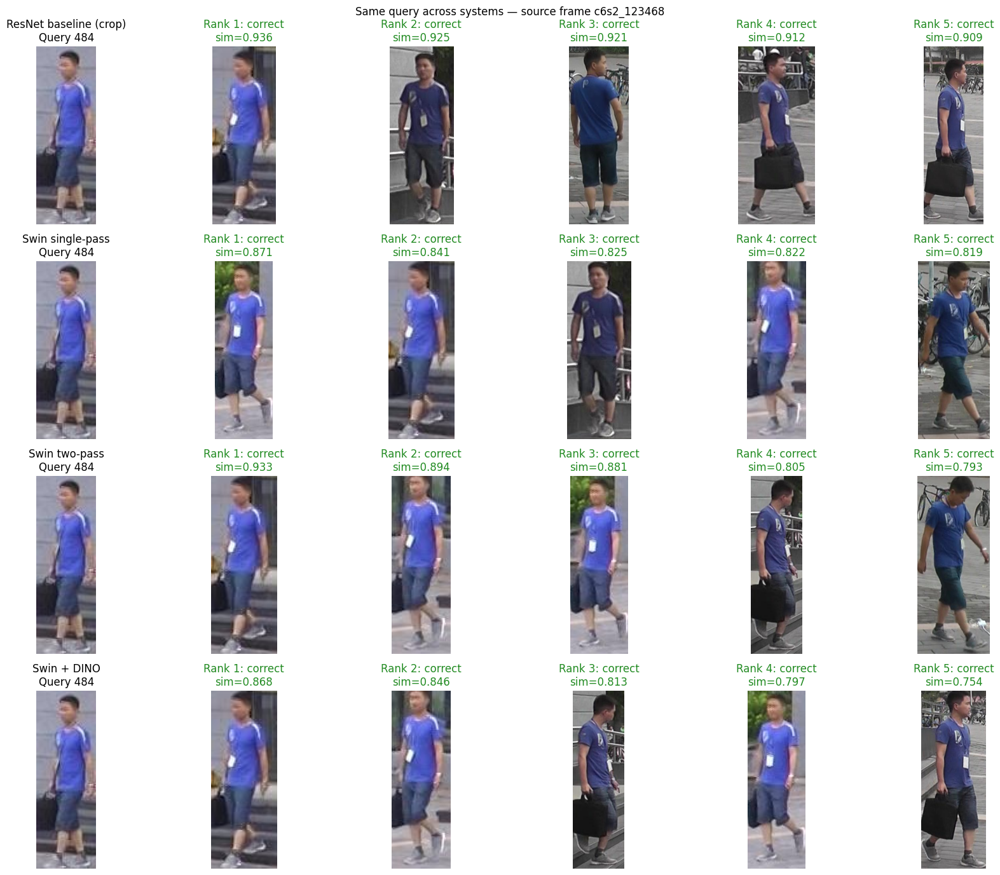

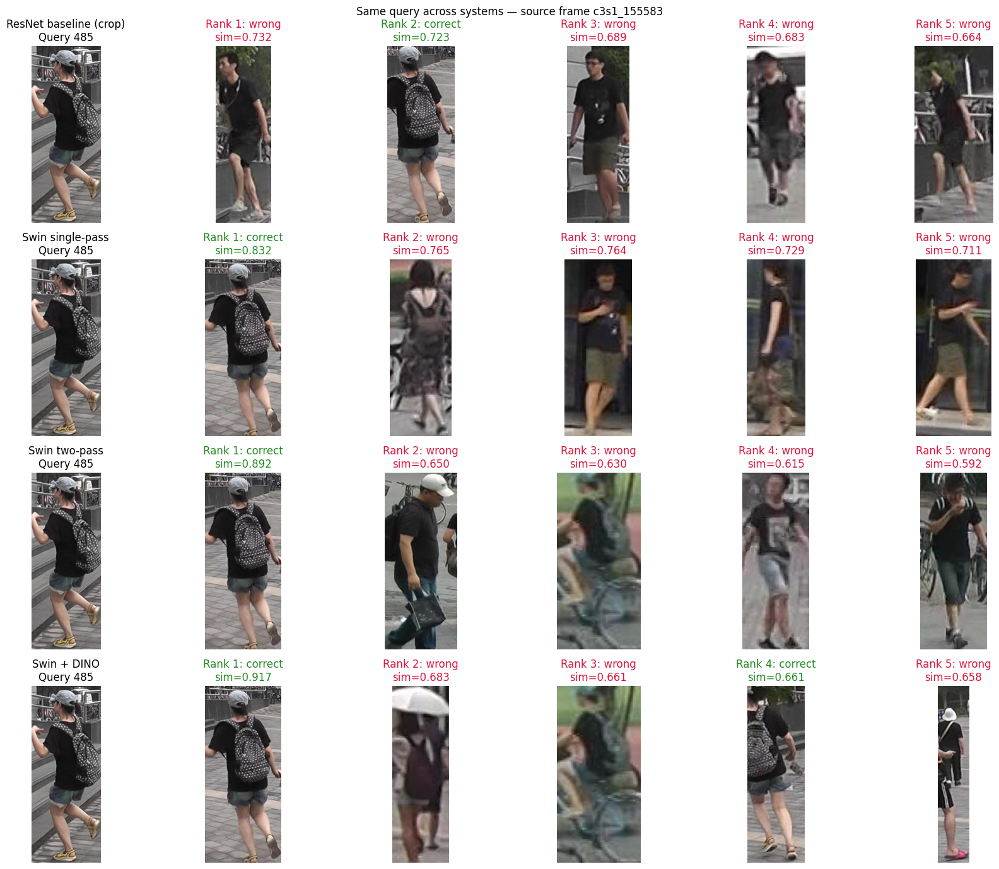

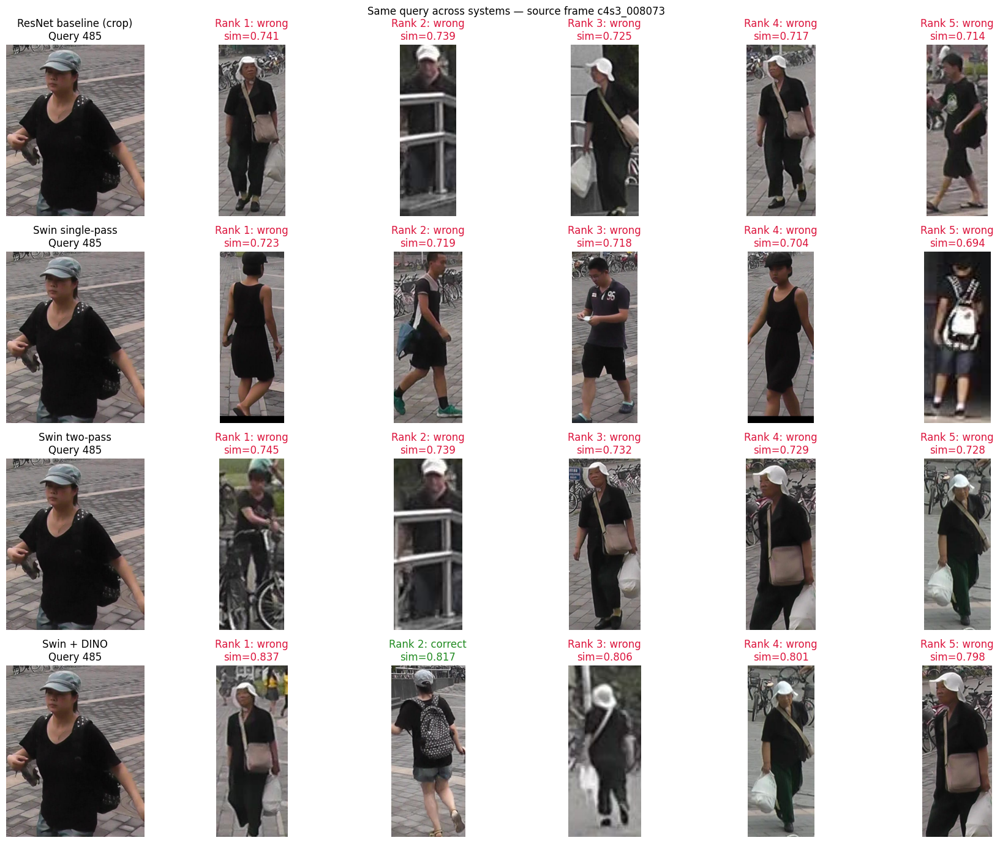

In [9]:
NUM_EXAMPLE_QUERIES = 10  # number of queries to show; results are saved for the first 100 official queries

# Ranked results of every system for the detected gallery.
matched = {s["name"]: retrieval_records[(s["name"], "detected")] for s in SYSTEMS}

# Keep queries available for all systems, in official query order.
key_sets = [{(r["identity"], r["frame"]) for r in rs} for rs in matched.values()]
common = set.intersection(*key_sets)
first = next(iter(matched.values()))
query_keys = list(dict.fromkeys((r["identity"], r["frame"]) for r in first
                                if (r["identity"], r["frame"]) in common))[:NUM_EXAMPLE_QUERIES]
if len(query_keys) < NUM_EXAMPLE_QUERIES:
    print("Only", len(query_keys), "common queries available")
(OUTPUT / "example_query_keys.json").write_text(json.dumps(query_keys))

# One figure per query: rows = systems, columns = query + top-5 retrievals.
for i, key in enumerate(query_keys):
    fig = plot_matched_query(matched, PRW_ROOT, key)
    fig.savefig(OUTPUT / f"query-comparison-{i:02d}.png", dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Observations
The ten queries show three people (IDs 479, 484, 485), each from several cameras.

- **Easy cases (identity 484, queries 4–8).** A distinctive blue T-shirt and a black bag. All systems retrieve the person at rank 1, and the two-pass and DINO systems are 5/5 correct on almost every query. The ResNet baseline sometimes inserts a different person in a similar blue top (query 4).
- **Mislabaled cases.** Query 1–3 (id 479, pink top + grey trousers): This shows a lot of mislabeling where the systems are able to retrieve the correct person.
- **Hard cases.** Query 9–10 (id 485): This becomes particularly difficult as the images to be retrieved show bag which is not very visible in query image though Swin + Dino is still able to get it in Rank 2.



<a id="conclusions"></a>
## 7. Conclusions
### Conclusions
1. **Decoupling detection and ReID works.** The fine-tuned Swin-T detector improves precision and recall over the jointly trained ResNet model, and the ReID network can then be specialised independently.
2. **The architectural ablation is the most important result.** On the same detector, a dedicated crop encoder (two-pass) beats ReID from frozen detector features (single-pass) by **+20.4 mAP / +28.9 top-1**. Detection features are not identity-discriminative enough.
3. **Backbone ablation.** Replacing the supervised Swin-T crop encoder with a fine-tuned **self-supervised DINOv3 ViT-S** (same upper/lower pooling) gives the best system: **54.1 mAP / 86.5 top-1** with detected boxes (59.5 / 88.1 with GT boxes).

   **Why upper/lower pooling.** The standard DINO image descriptor is its **CLS token**: one global vector that summarises the whole crop. The patch tokens hold the local, spatial information. In a pedestrian crop the person is upright and roughly centred, so the **top half of the patch grid mostly covers the upper body** (head, shirt, jacket, bag) and the **bottom half the legs** (trousers, skirt, shoes). Clothing colour and texture are often different between the two, and that difference is a strong identity cue. A single global vector can blur it: "red top + blue jeans" and "blue top + red trousers" have similar global colour statistics. Mean-pooling the patch tokens of each half separately and concatenating `[CLS, upper, lower]` gives the projection head an explicit, coarse "upper body / lower body" description. These are image halves, not detected body parts, so the cost is negligible. The Swin two-pass encoder uses the same split.

   **It improved over plain CLS features.** Several DINOv3 variants were trained during development. The table lists the fine-tuned ones that differ **only in the pooling**: same frozen detector, loss, sampler, crop size and trainable blocks. These runs used the earlier joint Swin-T detector and the evaluation code of the training notebooks, so their absolute values are lower than in section 4. The comparison *between rows* is fair.

   | DINOv3 ViT-S/16 pooling (fine-tuned, detected gallery) | Epochs | Test mAP | Test top-1 | Validation mAP |
   |---|---|---|---|---|
   | CLS token only | 50 | 48.3 | 84.7 | 68.4 |
   | CLS + mean of all patch tokens | 50 | 48.4 | 84.8 | 69.5 |
   | CLS + upper/lower halves | 50 | 49.4 | 85.2 | 71.1 |
   | CLS + three horizontal bands | 50 | 49.5 | 85.6 | 71.8 |
   | CLS token only | 120 | 50.0 | 84.7 | 73.2 |
   | **CLS + upper/lower halves (final)** | 120 | **51.1** | **85.7** | **75.4** |

   Adding the mean of *all* patch tokens changes almost nothing (+0.1 mAP), whereas splitting them into upper and lower halves gains about **+1 mAP**: +1.0 at 50 epochs and +1.2 at 120 epochs, with the GT-box gallery giving +1.4 (59.5 vs 58.1). The gain therefore comes from the **spatial split**, not from simply adding patch information. Three bands performed on par with two halves (+0.2 mAP, within run-to-run noise), so finer splits give diminishing returns. The upper/lower variant was the one trained for the longer 120-epoch run, and the same 120-epoch comparison against CLS-only also controls for the longer training budget. Earlier DINO experiments that did not reach this level are documented in `TRAINING.md` and not repeated here. They include frozen DINOv3 CLS features without fine-tuning (2.0 mAP), a frozen DINOv3 encoder with a trained projection (6.5 mAP), DINOv2 ViT-S/14 (29.9 mAP), hard-mined triplet/InfoNCE batches and an added identity cross-entropy loss (41.9 mAP). Only the best configuration is evaluated in this notebook.
4. Only about 5 mAP is lost to detection errors. The remaining errors are dominated by ReID: viewpoint changes and people wearing similar clothes.


### Possible improvements
Re-ranking (e.g. k-reciprocal), finer part-based pooling or attention over body parts, camera-aware training to handle viewpoint changes, and a single-pass model whose *backbone* is fine-tuned for ReID, which would make that ablation fairer.